In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

In [3]:
df = pd.read_csv("ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [5]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [7]:
# drop irrevelent columns
df.drop(columns=['UDI', 'Product ID'], inplace=True)

In [8]:
le = LabelEncoder()
df['Type'] = le.fit_transform(df['Type'])   # L, M, H → numeric

EDA

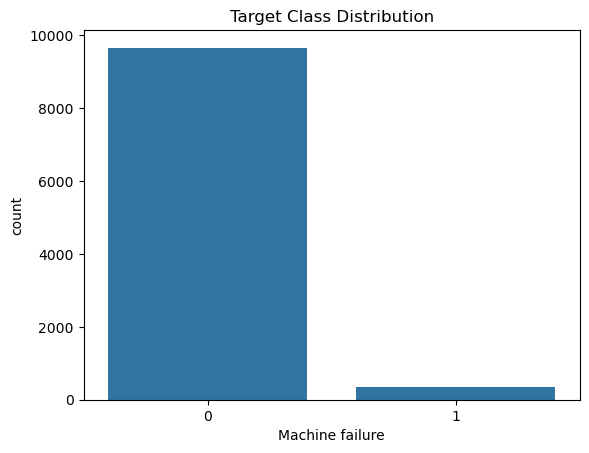

In [9]:
# target distribution
sns.countplot(x='Machine failure', data=df)
plt.title("Target Class Distribution")
plt.show()

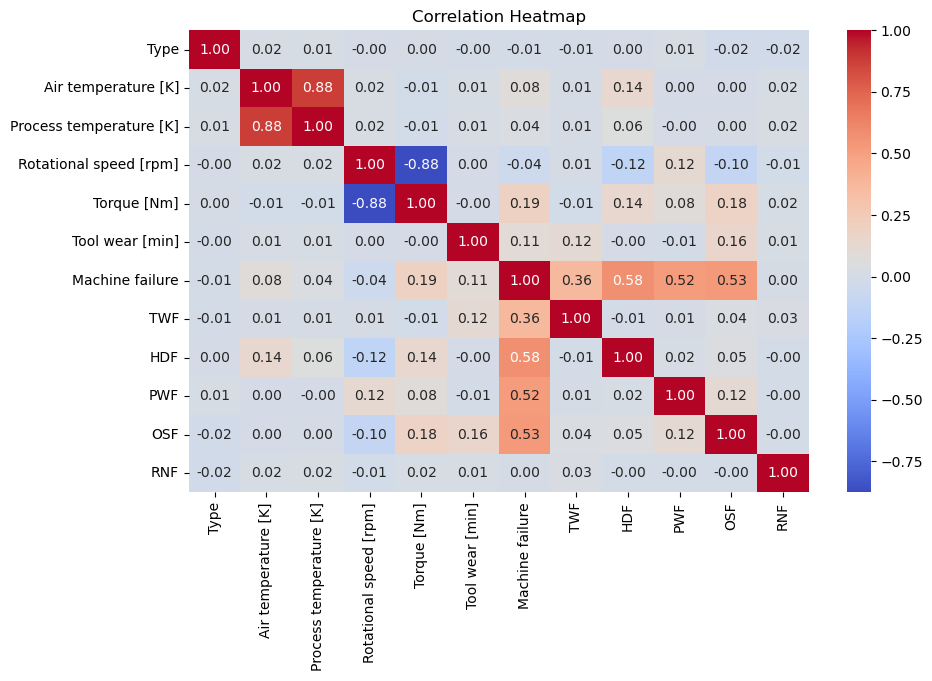

In [10]:
# correlation heatmap
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

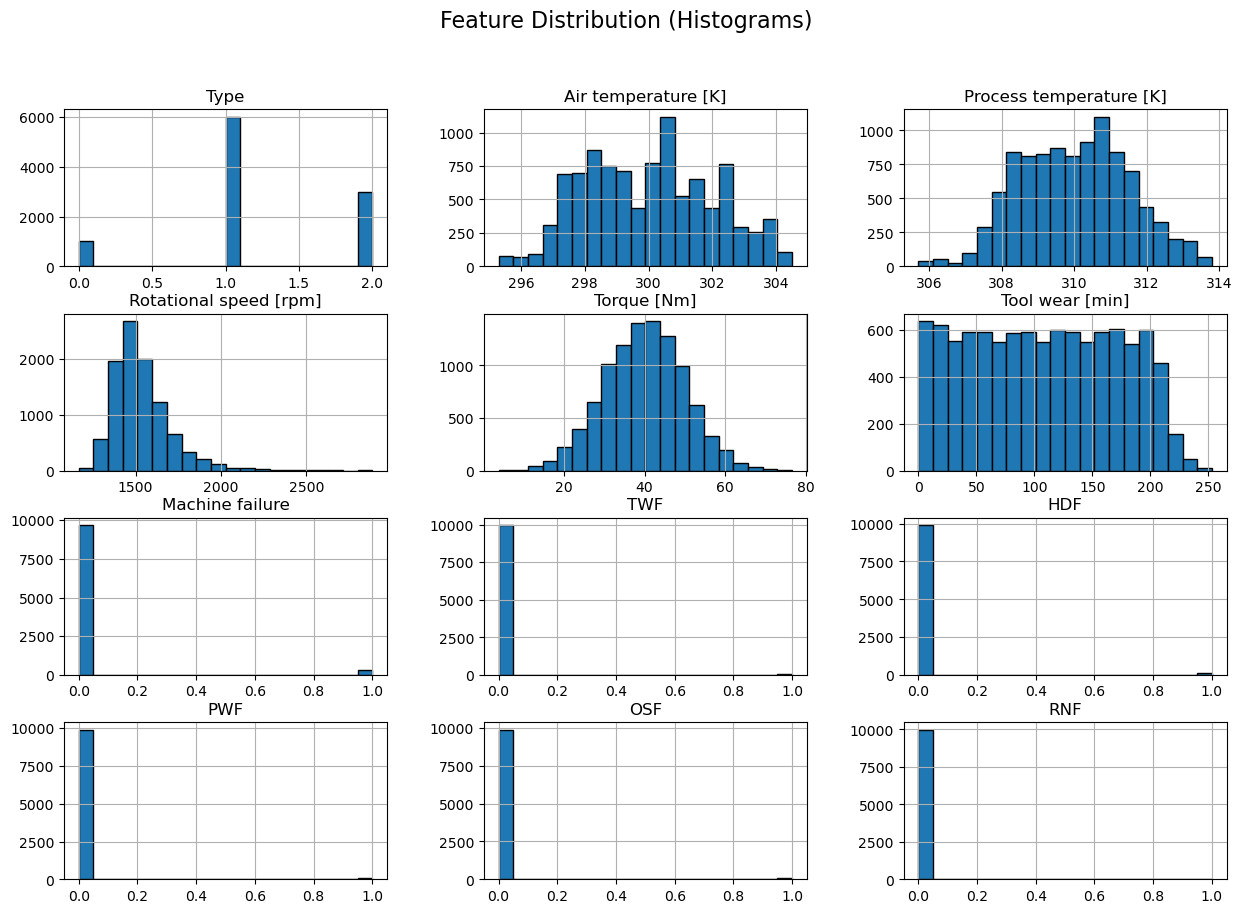

In [11]:
df.hist(figsize=(15,10), bins=20, edgecolor='black')
plt.suptitle("Feature Distribution (Histograms)", fontsize=16)
plt.show()

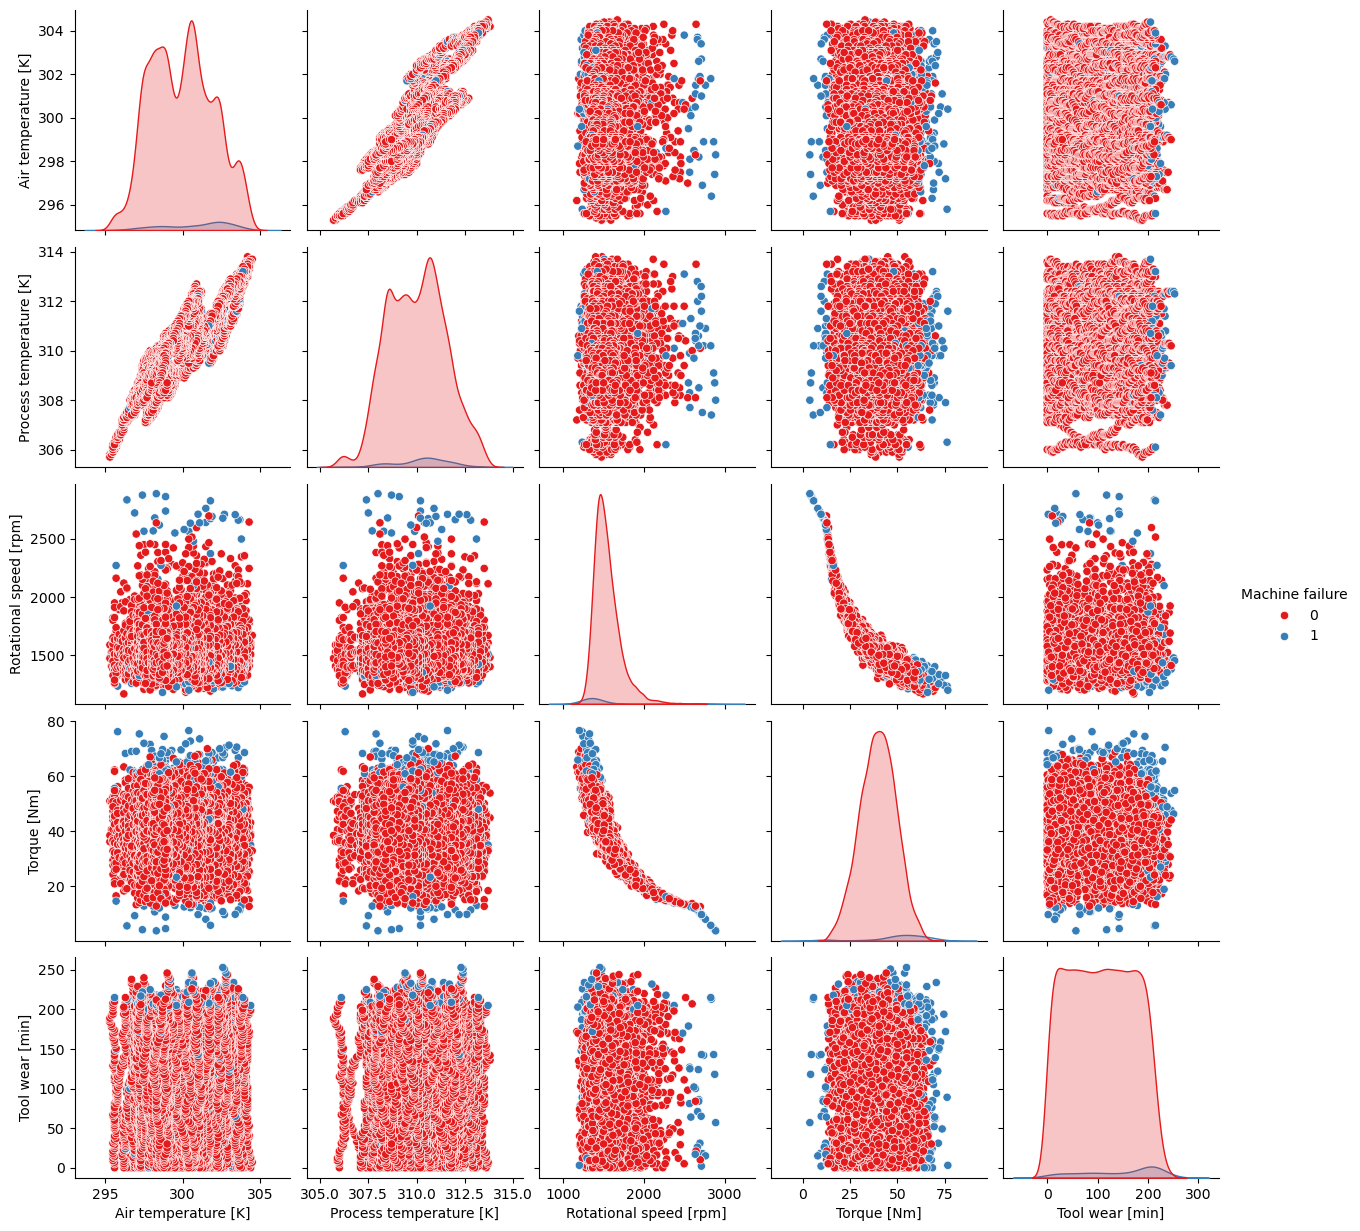

In [12]:
selected_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Machine failure'
]

sns.pairplot(
    df[selected_features],
    hue='Machine failure',
    diag_kind='kde',
    palette='Set1'
)
plt.show()

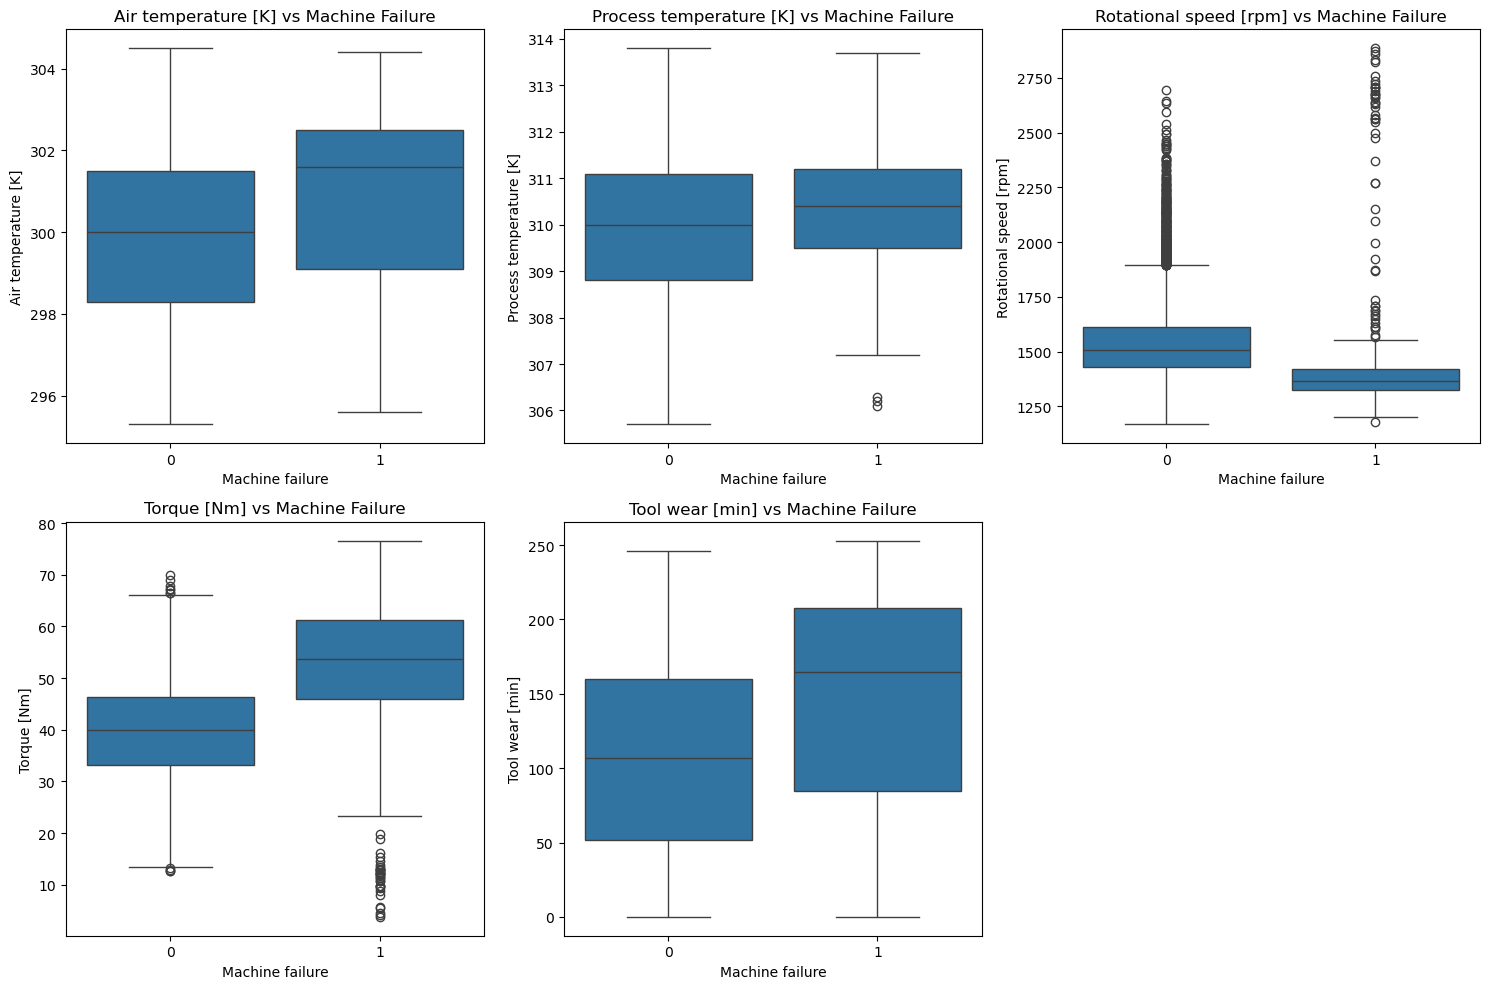

In [13]:
plt.figure(figsize=(15,10))

features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

for i, feature in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='Machine failure', y=feature, data=df)
    plt.title(f"{feature} vs Machine Failure")

plt.tight_layout()
plt.show()

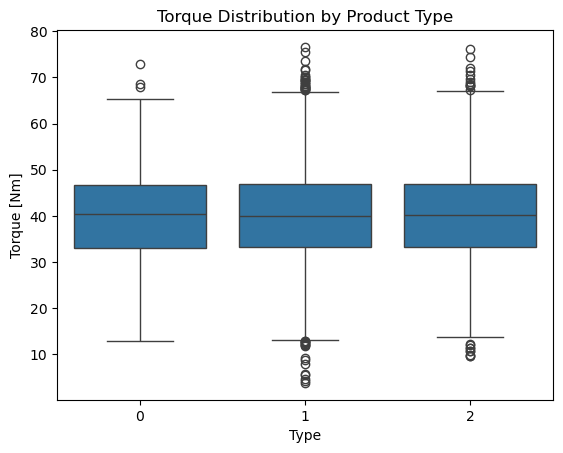

In [14]:
sns.boxplot(x='Type', y='Torque [Nm]', data=df)
plt.title("Torque Distribution by Product Type")
plt.show()

Outlier Treatment

In [15]:
numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

In [16]:
def detect_outliers_iqr(df, features):
    outlier_summary = {}
    for col in features:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        outlier_summary[col] = outliers.shape[0]

    return outlier_summary

In [17]:
outlier_counts = detect_outliers_iqr(df, numerical_features)
outlier_counts

{'Air temperature [K]': 0,
 'Process temperature [K]': 0,
 'Rotational speed [rpm]': 418,
 'Torque [Nm]': 69,
 'Tool wear [min]': 0}

In [18]:
def cap_outliers_iqr(df, features):
    df_capped = df.copy()

    for col in features:
        Q1 = df_capped[col].quantile(0.25)
        Q3 = df_capped[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        df_capped[col] = np.where(
            df_capped[col] < lower_bound,
            lower_bound,
            np.where(df_capped[col] > upper_bound, upper_bound, df_capped[col])
        )

    return df_capped

In [19]:
df = cap_outliers_iqr(df, numerical_features)

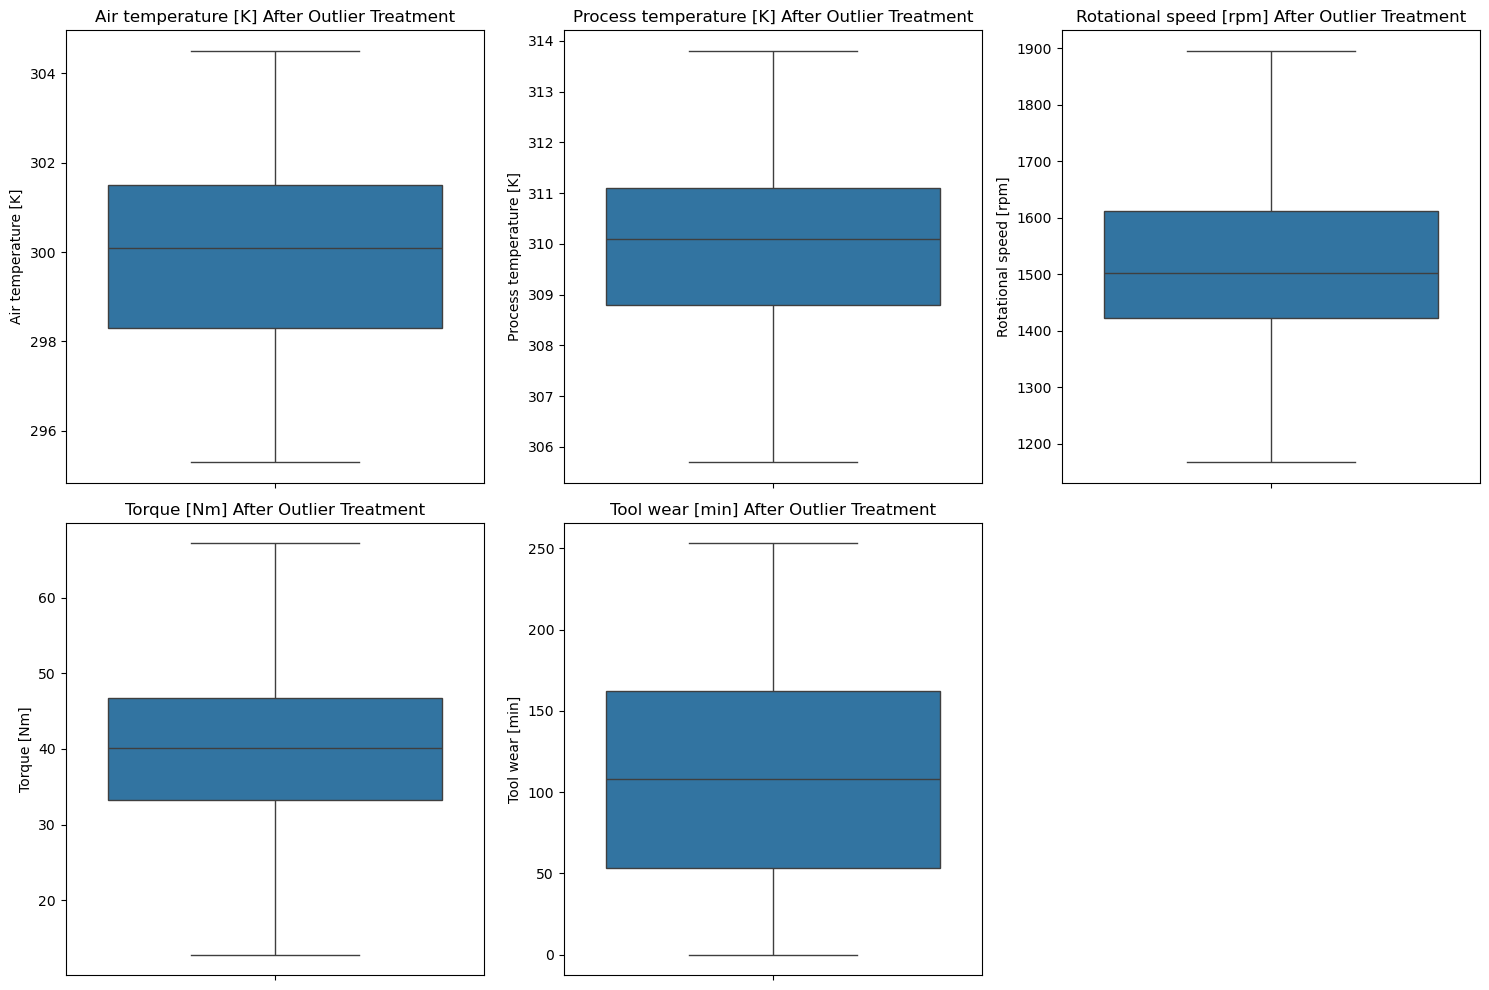

In [20]:
plt.figure(figsize=(15,10))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f"{col} After Outlier Treatment")

plt.tight_layout()
plt.show()

In [21]:
X = df.drop('Machine failure', axis=1)
y = df['Machine failure']

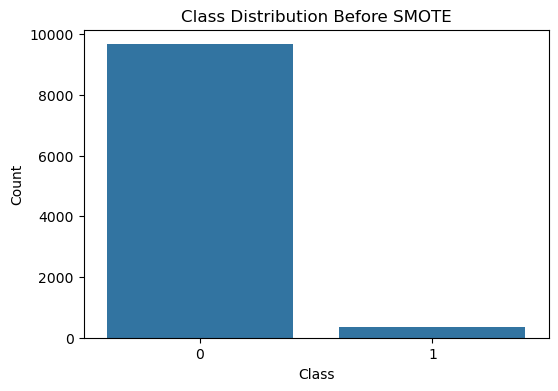

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.countplot(x=y)
plt.title("Class Distribution Before SMOTE")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [23]:
# data handling
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("Before SMOTE:", y.value_counts())
print("After SMOTE:", pd.Series(y_resampled).value_counts())

Before SMOTE: Machine failure
0    9661
1     339
Name: count, dtype: int64
After SMOTE: Machine failure
0    9661
1    9661
Name: count, dtype: int64


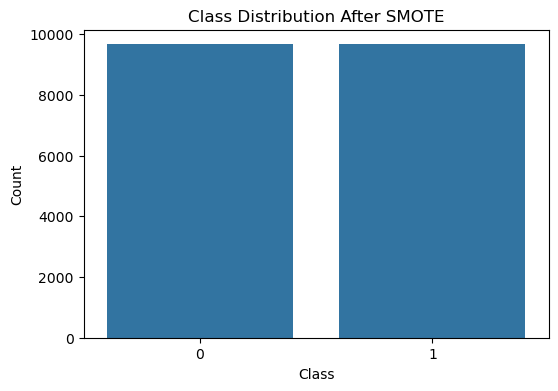

In [24]:
# count plot
plt.figure(figsize=(6,4))
sns.countplot(x=y_resampled)
plt.title("Class Distribution After SMOTE")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled,
    test_size=0.2,
    random_state=42,
    stratify=y_resampled
)

In [26]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

models

In [27]:
models = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "XGBoost": XGBClassifier()
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"{name} Accuracy: {accuracy_score(y_test, y_pred):.4f}")

Logistic Regression Accuracy: 0.9201
KNN Accuracy: 0.9661
SVM Accuracy: 0.9464
Naive Bayes Accuracy: 0.8673
Decision Tree Accuracy: 0.9713
Random Forest Accuracy: 0.9777
AdaBoost Accuracy: 0.9488
Gradient Boosting Accuracy: 0.9609
XGBoost Accuracy: 0.9850


With Hyperparameter Tuning

In [28]:
models_params = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            'max_depth': [None, 5, 10],
            'min_samples_split': [2, 5, 10],
            'criterion': ['gini', 'entropy']
        }
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            'n_estimators': [100, 200],
            'max_depth': [None, 10],
            'min_samples_split': [2, 5]
        }
    ),

    "XGBoost": (
        XGBClassifier(
            use_label_encoder=False,
            eval_metric='logloss',
            random_state=42
        ),
        {
            'n_estimators': [100, 200],
            'max_depth': [3, 6],
            'learning_rate': [0.01, 0.1],
            'subsample': [0.8, 1.0],
            'colsample_bytree': [0.8, 1.0]
        }
    )
}

# ===============================
# 5. GRID SEARCH FOR ALL MODELS
# ===============================
results = []
best_estimators = {}

for model_name, (model, params) in models_params.items():
    print(f"\n🔍 Tuning {model_name}...")

    grid = GridSearchCV(
        model,
        params,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    results.append([model_name, grid.best_params_, acc])
    best_estimators[model_name] = best_model

# ===============================
# 6. RESULTS COMPARISON
# ===============================
results_df = pd.DataFrame(
    results,
    columns=["Model", "Best Parameters", "Test Accuracy"]
).sort_values(by="Test Accuracy", ascending=False)

print("\n📊 FINAL MODEL COMPARISON")
print(results_df)

# ===============================
# 7. BEST MODEL
# ===============================
best_model_name = results_df.iloc[0]["Model"]
final_model = best_estimators[best_model_name]

print(f"\n🏆 BEST MODEL: {best_model_name}")


🔍 Tuning Decision Tree...

🔍 Tuning Random Forest...

🔍 Tuning XGBoost...


/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:199: UserWarning: [19:22:35] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:199: UserWarning: [19:22:35] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:199: UserWarning: [19:22:35] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:199: UserWarning: [19:22:35] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i


📊 FINAL MODEL COMPARISON
           Model                                    Best Parameters  \
2        XGBoost  {'colsample_bytree': 0.8, 'learning_rate': 0.1...   
1  Random Forest  {'max_depth': None, 'min_samples_split': 2, 'n...   
0  Decision Tree  {'criterion': 'entropy', 'max_depth': None, 'm...   

   Test Accuracy  
2       0.983700  
1       0.978266  
0       0.972833  

🏆 BEST MODEL: XGBoost


In [29]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1933
           1       0.98      0.98      0.98      1932

    accuracy                           0.98      3865
   macro avg       0.98      0.98      0.98      3865
weighted avg       0.98      0.98      0.98      3865

ROC-AUC: 0.9990778020198385


Confusion Matrix (Best Model)

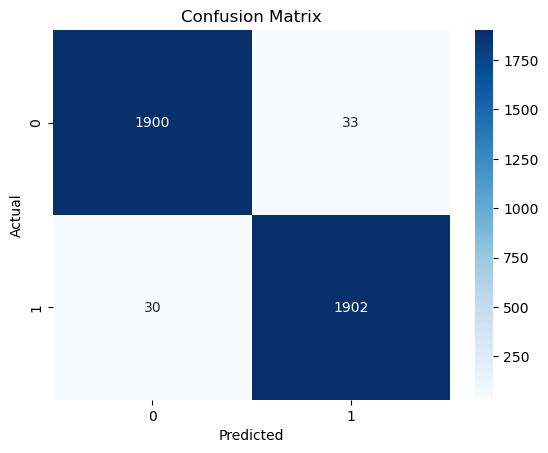

In [30]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [31]:
import joblib
joblib.dump(best_model,"predictive maintenance.pkl")

['predictive maintenance.pkl']

In [32]:
joblib.dump(scaler,"scaler.pkl")

['scaler.pkl']

In [33]:
joblib.dump(le,"le.pkl")

['le.pkl']

In [34]:
#!pip install streamlit joblib